# Topic quality: coherence and exclusivity (K=12)
Evaluate the current K=12 topics using the latest analysis data. The two corpora are fitted separately using their original LDA settings. This notebook checks individual topic quality only.

C_v coherence measures whether top words tend to occur together. Exclusivity is the mean share of each top-10 word assigned to its topic across the 12 topics. Both are descriptive, in-sample measures; topic meaning still needs inspection of texts.

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.metrics.pairwise import cosine_similarity
from gensim.corpora import Dictionary
from gensim.models import CoherenceModel
import sklearn, gensim

project = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "notebook").is_dir() and (p / "data").is_dir())
output = project / "data" / "analysis_results" / "lda_topic_quality"
(project / "data" / "generated_figures" / output.relative_to(project / "data" / "analysis_results")).mkdir(parents=True, exist_ok=True)
(project / "data" / "model_cache" / output.relative_to(project / "data" / "analysis_results")).mkdir(parents=True, exist_ok=True)
output.mkdir(parents=True, exist_ok=True)
ks = [12]
titles = {"official_media": "Official Media", "weibo_posts": "Weibo Posts"}
colors = {"official_media": "#346d8c", "weibo_posts": "#c67c53"}
labels = pd.read_csv(project / "data" / "analysis_results" / "lda_k12_presentation" / "k12_topics_with_interpretations.csv")
plt.rcParams.update({"font.family": "Arial Unicode MS", "font.size": 11})


## 1. Calculate topic quality
Use the top 10 words and Gensim C_v coherence with a 110-token window. Exclusivity is the average of beta(topic, word) / sum_topics beta(topic, word) for each topic's top 10 words. It ranges from 0 to 1 and is a mean word-share measure, not an STM FREX score. The notebook checks all reconstructed top-10 lists against the saved K=12 results.

In [2]:
def evaluate_corpus(corpus, min_df):
    source = project / "data" / f"{corpus}_analysis.csv"
    data = pd.read_csv(source, usecols=["tokens", "year"]).dropna(subset=["tokens"])
    vectorizer = CountVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False,
                                 min_df=min_df, max_df=0.85, max_features=5000)
    X = vectorizer.fit_transform(data["tokens"])
    keep = X.getnnz(axis=1) > 0
    X = X[keep]
    texts = data.loc[keep, "tokens"].str.split().tolist()
    words = vectorizer.get_feature_names_out()
    settings = f"{ks}|{min_df}|0.85|5000|online|12|512|42|4|{sklearn.__version__}"
    signature = hashlib.sha256(source.read_bytes() + settings.encode()).hexdigest()
    cache_path = (project / "data" / "model_cache" / output.relative_to(project / "data" / "analysis_results")) / f"{corpus}_fits.npz"
    cached = {}
    if cache_path.exists():
        with np.load(cache_path, allow_pickle=False) as archive:
            if str(archive["signature"]) == signature:
                cached = {key: archive[key] for key in archive.files}
    fits, top_words = {}, {}
    arrays = {"signature": np.array(signature), "words": words.astype(str)}
    for k in ks:
        if f"beta_{k}" in cached:
            beta, prevalence = cached[f"beta_{k}"], cached[f"prevalence_{k}"]
        else:
            model = LatentDirichletAllocation(n_components=k, learning_method="online", max_iter=12,
                                             batch_size=512, random_state=42, n_jobs=4).fit(X)
            beta = model.components_ / model.components_.sum(axis=1, keepdims=True)
            prevalence = model.transform(X).mean(axis=0) * 100
        indices = beta.argsort(axis=1)[:, -10:][:, ::-1]
        top_words[k] = words[indices].tolist()
        original = pd.read_csv(project / "data" / "analysis_results" / f"lda_{corpus}" / f"k{k}_top10_keywords.csv")
        assert np.array_equal(words[indices], original.iloc[:, 1:].to_numpy()), "Saved topics differ."
        if k == 12:
            old = pd.read_csv(project / "data" / "analysis_results" / f"lda_{corpus}" / "k12_topic_prevalence.csv")
            assert np.allclose(prevalence, old["prevalence_pct"], atol=0.0051)
        fits[k] = {"beta": beta, "prevalence": prevalence, "indices": indices}
        arrays[f"beta_{k}"], arrays[f"prevalence_{k}"] = beta, prevalence
        print(f"{titles[corpus]}: K={k} verified.", flush=True)
    np.savez_compressed(cache_path, **arrays)
    coherence = CoherenceModel.for_topics([top_words[k] for k in ks],
                 texts=texts, dictionary=Dictionary(texts), coherence="c_v", topn=10,
                 window_size=110, processes=1)
    rows = []
    for k in ks:
        coherence.topics = top_words[k]
        cv = coherence.get_coherence_per_topic()
        beta = fits[k]["beta"]
        word_share = beta / beta.sum(axis=0, keepdims=True)
        exclusivity = np.take_along_axis(word_share, fits[k]["indices"], axis=1).mean(axis=1)
        for t in range(k):
            rows.append({"corpus": corpus, "k": k, "topic": t + 1,
                         "coherence_cv": cv[t], "exclusivity": exclusivity[t],
                         "prevalence_pct": fits[k]["prevalence"][t],
                         "top10_keywords": " / ".join(top_words[k][t]),
                         "n_documents": X.shape[0], "vocabulary_size": X.shape[1]})
    print(f"{titles[corpus]}: coherence and exclusivity completed.")
    return fits, top_words, pd.DataFrame(rows)


In [3]:
official_fits, official_words, official_quality = evaluate_corpus("official_media", 5)


Official Media: K=12 verified.


Official Media: coherence and exclusivity completed.


In [4]:
weibo_fits, weibo_words, weibo_quality = evaluate_corpus("weibo_posts", 10)


Weibo Posts: K=12 verified.


Weibo Posts: coherence and exclusivity completed.


In [5]:
quality = pd.concat([official_quality, weibo_quality], ignore_index=True)
assert set(quality["k"]) == {12} and len(quality) == 24
quality.to_csv(output / "topic_quality_k12.csv", index=False, encoding="utf-8-sig")
display(quality[["corpus", "topic", "coherence_cv", "exclusivity"]].round(3))


,corpus,topic,coherence_cv,exclusivity
0,official_media,1,0.652,0.507
1,official_media,2,0.452,0.265
2,official_media,3,0.492,0.437
3,official_media,4,0.772,0.573
4,official_media,5,0.797,0.621
5,official_media,6,0.720,0.498
6,official_media,7,0.648,0.540
7,official_media,8,0.755,0.513
8,official_media,9,0.806,0.541
9,official_media,10,0.552,0.473


## 2. Plot the 12 topics
Higher coherence and exclusivity are favorable, but there is no universal cutoff.

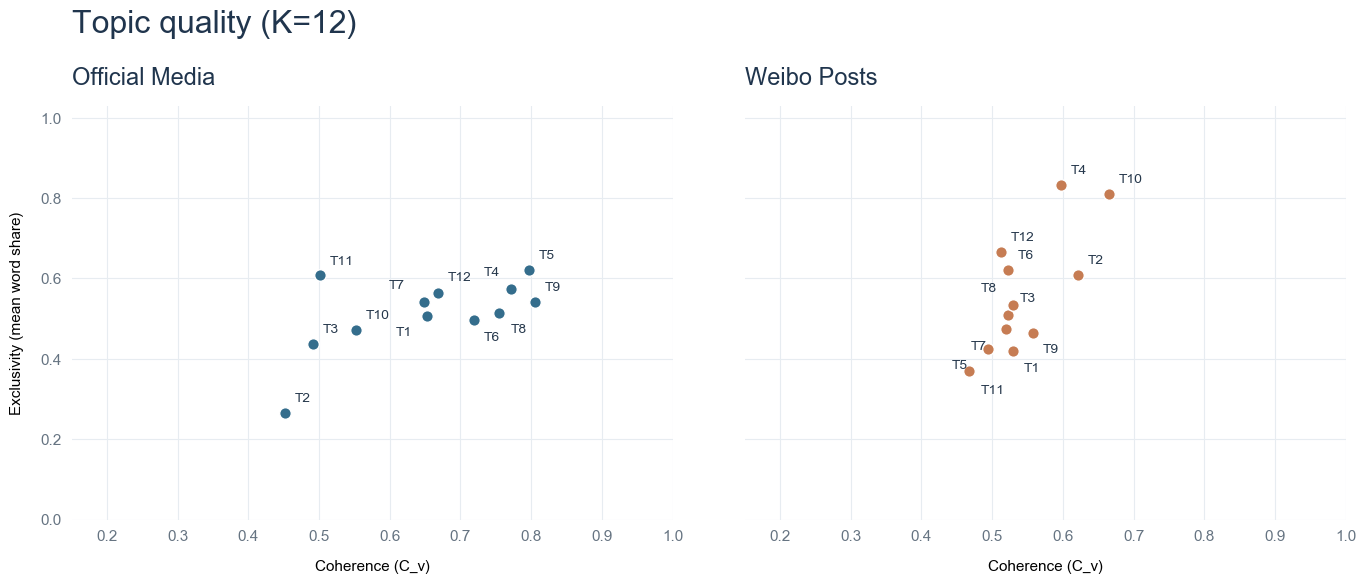

In [ ]:
def clean_axes(ax):
    ax.grid(color="#e7ecf1", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0, colors="#667482", pad=7)
    for spine in ax.spines.values():
        spine.set_visible(False)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True, facecolor="white")
for ax, corpus in zip(axes, titles):
    data = quality[(quality["corpus"] == corpus) & (quality["k"] == 12)]
    ax.scatter(data["coherence_cv"], data["exclusivity"], s=70,
               color=colors[corpus], edgecolor="white", zorder=3)
    offsets = {
        "official_media": {1: (-22, -14), 4: (-20, 10), 6: (7, -15),
                           7: (-25, 10), 8: (8, -14), 12: (7, 9)},
        "weibo_posts": {1: (8, -15), 3: (8, 10), 5: (-26, -14),
                        7: (-25, -15), 8: (-23, 10), 9: (7, -14), 11: (8, -16)},
    }
    for row in data.itertuples():
        ax.annotate(f"T{row.topic}", (row.coherence_cv, row.exclusivity),
                    xytext=offsets[corpus].get(row.topic, (7, 8)), textcoords="offset points", fontsize=10, color="#26384c")
    ax.set_title(titles[corpus], loc="left", fontsize=17, fontweight="bold", color="#20354d", pad=15)
    ax.set_xlabel("Coherence (C_v)", labelpad=12)
    ax.set_xlim(0.15, 1.0)
    ax.set_ylim(0.0, 1.03)
    clean_axes(ax)
axes[0].set_ylabel("Exclusivity (mean word share)", labelpad=12)
fig.suptitle("Topic quality (K=12)", x=0.07, y=0.99, ha="left", fontsize=23, color="#20354d")
fig.subplots_adjust(left=0.07, right=0.98, top=0.83, bottom=0.14, wspace=0.12)
fig.savefig((project / "data" / "generated_figures" / output.relative_to(project / "data" / "analysis_results")) / "k12_coherence_exclusivity.png", dpi=220, bbox_inches="tight")
plt.show()


## Reference
[Gensim CoherenceModel documentation](https://radimrehurek.com/gensim/models/coherencemodel.html). The two corpora differ in length, genre and vocabulary; the side-by-side panels support within-corpus topic inspection.